# XGBoost Modeling — Tuning, Stability & Error Analysis

**Mục tiêu**

> **Single source of truth:** mọi logic (load feature, chia tập, kiểm tra leakage, tuning, đánh giá, cờ sự kiện, Ljung-Box) nằm trong `src/train_xgboost.py`. Notebook chỉ **gọi lại các hàm** đó (`tx.<hàm>`) và lo phần trình bày: bảng, biểu đồ, nhận xét. Sửa logic thì sửa ở script, notebook tự cập nhật theo.

**Quy ước**

| Hạng mục | Quy ước | Nguồn |
|---|---|---|
| Tuần | Thứ Hai là ngày đầu tuần, 366 tuần | `preprocess.py` |
| Chia tập | Theo `split_year`: Train ≤ 2022 / Val2023 / Val2024 / Test2025 | `preprocess.SplitConfig` |
| Feature | 42 cột, tất cả `shift(1)` | `feature_engineering.build_feature_matrix()` |
| Kiểu dự báo | One-step-ahead (tại tuần t chỉ biết actual đến t−1) | `train_sarima.forecast_1step_ahead()` |
| Chọn model | RMSE Val2023 thấp nhất; chênh ≤ 3% thì chọn cấu hình đơn giản hơn | `train_sarima.select_best_model()` |

**Cách chạy**

| Mục đích | Cách làm | Thời gian |
|---|---|---|
| Chỉ xem kết quả | Mở file; output đã lưu sẵn | 0 giây |
| Chạy lại nhanh (mặc định) | `RUN_TUNING = False` → nạp `best_params_*.json` + `tuning_results_*.csv` do script sinh ra, rồi refit model | ~20 giây |
| Chạy lại toàn bộ tuning | Đặt `RUN_TUNING = True`, hoặc: `papermill notebooks/03_xgboost_modeling.ipynb out.ipynb -p RUN_TUNING True` | ~5 phút |

**Điều kiện:** đã chạy `python src/preprocess.py`. Với `RUN_TUNING = False`, cần có thêm `outputs/xgboost/` (sinh ra bởi `python src/train_xgboost.py --series all`, có sẵn trong repo).

## 0. Thiết lập môi trường

In [ ]:
import os
import sys
import importlib
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

# Tìm thư mục gốc project (chứa src/train_xgboost.py) và chdir vào đó,
ROOT = Path.cwd().resolve()
while not (ROOT / "src" / "train_xgboost.py").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if not (ROOT / "src" / "train_xgboost.py").exists():
    raise FileNotFoundError("Không tìm thấy thư mục gốc project (cần src/train_xgboost.py)")
os.chdir(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
assert (ROOT / "data/processed/weekly_total.csv").exists(), \
    "Chưa có data/processed — hãy chạy: python src/preprocess.py"

import feature_engineering
import train_xgboost as tx
importlib.reload(feature_engineering)
tx = importlib.reload(tx)

COLORS = {"actual": "#3d3d3a", "xgb": "#2a78d6", "sarima": "#eb6834", "mean": "#8a8984"}
sns.set_theme(style="whitegrid", rc={"grid.color": "#e6e5e0", "axes.edgecolor": "#c9c8c2",
                                     "axes.titleweight": "bold", "axes.titlesize": 11})

print("Project root :", ROOT.name)
print("xgboost      :", xgboost.__version__, "| pandas:", pd.__version__)

Project root : retail-revenue-forecasting
xgboost      : 3.2.0 | pandas: 3.0.2


### Tham số notebook

In [2]:
# ── Parameters (papermill) ──────────────────────────────────────────────────
SERIES     = ["total", "online", "store", "mobile"]
RUN_TUNING = False   # False: nạp kết quả tuning đã lưu (~20 giây) | True: chạy lại random search (~5 phút)
N_ITER     = 60      # số cấu hình random search khi RUN_TUNING = True (giống script)
TOP_N      = 10      # số tuần lỗi lớn nhất mỗi kỳ

## 1. Tải ma trận đặc trưng

`tx.prepare_series(s)` làm 3 việc:

1. Gọi `build_feature_matrix()` để lấy ma trận đặc trưng.
2. Chia tập bằng `tx.split_frame()`, có assert số tuần của từng tập.
3. Chạy toàn bộ kiểm tra leakage (chi tiết ở mục 2).


In [3]:
matrices, splits, FEATURES = {}, {}, {}
for s in SERIES:
    matrices[s], splits[s], FEATURES[s] = tx.prepare_series(s, quiet=True)

FEATURE_COLS = FEATURES[SERIES[0]]
assert all(f == FEATURE_COLS for f in FEATURES.values()), "Các chuỗi có danh sách feature khác nhau"

print(f"Số feature: {len(FEATURE_COLS)}")
display(pd.DataFrame({
    s: {"rows": len(m), "first_week": m.index.min().date(), "last_week": m.index.max().date(),
        "n_features": len(FEATURES[s])}
    for s, m in matrices.items()
}).T)

fc = pd.Series(FEATURE_COLS)
display(fc.groupby(fc.map(tx.feature_group)).agg(n="count", columns=lambda x: ", ".join(x)))

Số feature: 42


,rows,first_week,last_week,n_features
total,366,2018-12-31,2025-12-29,42
online,366,2018-12-31,2025-12-29,42
store,366,2018-12-31,2025-12-29,42
mobile,366,2018-12-31,2025-12-29,42


,n,columns
COVID,2,"is_covid_period, is_covid_shock"
Lag,14,"lag_revenue_1, lag_revenue_2, lag_revenue_3, l..."
Outlier,1,is_lag_1_high_revenue
Rolling,16,"rolling_mean_4, rolling_std_4, rolling_min_4, ..."
Time,7,"week_of_year, month, quarter, year, week_sin, ..."
YoY/MoM,2,"lag_52_ratio, lag_4_ratio"


In [ ]:
# Xem nhanh vài cột của chuỗi Total
matrices["total"][["target_revenue", "split_year", "lag_revenue_1", "lag_revenue_52",
                   "rolling_mean_4", "week_of_year", "is_covid_period", "lag_4_ratio"]].iloc[50:56]

,target_revenue,split_year,lag_revenue_1,lag_revenue_52,rolling_mean_4,week_of_year,is_covid_period,lag_4_ratio
week_start,,,,,,,,
2019-12-16,3168.302728,2019,1938.131416,NaN,2733.696510,51,0,0.742232
2019-12-23,2799.080538,2019,3168.302728,NaN,2872.967465,52,0,0.653792
2019-12-30,3778.876997,2019,2799.080538,3376.161565,2361.228308,1,0,1.818295
2020-01-06,3875.550000,2020,3778.876997,3730.699588,2921.097920,2,0,1.949753
2020-01-13,3026.477297,2020,3875.550000,4628.662425,3405.452565,3,0,1.223226
2020-01-20,2739.731257,2020,3026.477297,1900.318903,3369.996208,4,0,1.081240


## 2. Tách tập theo thời gian & kiểm tra leakage

Các tập được chia theo `split_year`, đúng `SplitConfig` của `preprocess.py`. Một tuần thuộc về năm của giao dịch sớm nhất trong tuần đó, nên Val2024 có 53 tuần.

| Giai đoạn | Fit trên | Dự báo | Vai trò |
|---|---|---|---|
| Selection | Train 2019–2022 | Val2023 | Chọn siêu tham số |
| Stability | 2019–2023 | Val2024 | Kiểm tra độ ổn định, **không tune lại** |
| Final | 2019–2024 | Test2025 | Chỉ chạy trong script; notebook không đụng đến Test2025 |

In [5]:
pd.DataFrame([
    {"split": name, "n_weeks": len(f), "from": f.index.min().date(), "to": f.index.max().date(),
     "expected": tx.EXPECTED_SPLIT_SIZES[name]}
    for name, f in splits["total"].items()
])

,split,n_weeks,from,to,expected
0,train_2019_2022,209,2018-12-31,2022-12-26,209
1,val_2023,52,2023-01-02,2023-12-25,52
2,train_2019_2023,261,2018-12-31,2023-12-25,261
3,val_2024,53,2024-01-01,2024-12-30,53
4,train_2019_2024,314,2018-12-31,2024-12-30,314
5,test_2025,52,2025-01-06,2025-12-29,52


### Kiểm tra Data Leakage

1. **Không có target trong feature** (`tx.get_feature_cols`): danh sách feature không chứa `revenue` hay `target_revenue`.
2. **Biên giữa các tập** (`tx.check_split_boundaries`): `lag_revenue_1` của tuần đầu Val2023 / Val2024 / Test2025 phải bằng doanh thu thật của tuần ngay trước đó. Hàm này cũng kiểm tra các tập không chồng lấn thời gian.
3. **Perturbation test** (`tx.assert_no_target_leakage`): nhân doanh thu tuần t lên ×10 rồi tính lại feature. Feature của chính tuần t phải giữ nguyên. Thử trên 3 tuần mỗi chuỗi.

In [6]:
leak_rows = []
for s in SERIES:
    tx.get_feature_cols(matrices[s])
    tx.check_split_boundaries(splits[s])
    probes = tx.assert_no_target_leakage(s, splits[s])
    leak_rows.append({"series": s, "target_not_in_features": "PASS", "split_boundaries": "PASS",
                      "perturbation": "PASS", "probe_weeks": ", ".join(str(p.date()) for p in probes)})
pd.DataFrame(leak_rows).set_index("series")

,target_not_in_features,split_boundaries,perturbation,probe_weeks
series,,,,
total,PASS,PASS,PASS,"2021-11-15, 2023-03-13, 2024-01-01"
online,PASS,PASS,PASS,"2021-11-15, 2023-03-13, 2024-01-01"
store,PASS,PASS,PASS,"2021-11-15, 2023-03-13, 2024-01-01"
mobile,PASS,PASS,PASS,"2021-11-15, 2023-03-13, 2024-01-01"


## 3. Huấn luyện & Tuning

### 3.1. Không gian siêu tham số & luật chọn

Không gian siêu tham số lấy từ `tx.PARAM_SPACE`, tham số cố định từ `tx.FIXED_PARAMS`.

- `ParameterSampler` lấy 60 cấu hình với seed 42, dùng chung cho 4 chuỗi.
- Mỗi cấu hình: fit trên Train 2019–2022, chấm RMSE trên Val2023. Song song tính `cv_rmse_train` bằng TimeSeriesSplit bên trong Train; chỉ số này chỉ để chẩn đoán.
- **Luật chọn (`tx.select_best_config`, giống SARIMA):** lấy RMSE Val2023 thấp nhất. Nếu có nhiều cấu hình chênh không quá 3%, chọn cấu hình đơn giản nhất theo thứ tự: `max_depth` nhỏ hơn → `n_estimators` ít hơn → `reg_lambda` lớn hơn.
- Dự báo được ép về `float64` trong `tx.fit_predict`, nên CSV lưu đúng giá trị và cột `residual` khớp tuyệt đối với `actual − xgb_forecast`.
- **`RUN_TUNING = False`** (mặc định): dùng `tx.load_saved_tuning` để nạp best params và bảng tuning đã lưu. Hàm này có kiểm tra JSON khớp với dòng `selected` trong CSV.
- **`RUN_TUNING = True`:** gọi `tx.tune` để chạy lại random search, khoảng 80 giây mỗi chuỗi.

In [7]:
n_grid = int(np.prod([len(v) for v in tx.PARAM_SPACE.values()]))
print(f"Full grid = {n_grid:,} tổ hợp → random search {N_ITER} cấu hình (seed {tx.RANDOM_STATE})")
print("Fixed params:", tx.FIXED_PARAMS)
pd.DataFrame({k: [", ".join(map(str, v))] for k, v in tx.PARAM_SPACE.items()}, index=["values"]).T

Full grid = 34,560 tổ hợp → random search 60 cấu hình (seed 42)
Fixed params: {'objective': 'reg:squarederror', 'tree_method': 'hist', 'random_state': 42, 'n_jobs': 1}


,values
n_estimators,"100, 200, 300, 500, 800"
learning_rate,"0.01, 0.03, 0.05, 0.1"
max_depth,"2, 3, 4, 5"
min_child_weight,"1, 3, 5, 10"
subsample,"0.6, 0.8, 1.0"
colsample_bytree,"0.5, 0.7, 1.0"
reg_lambda,"0.0, 1.0, 5.0, 10.0"
reg_alpha,"0.0, 0.1, 1.0"


In [8]:
import time

best_params, tuning_tables = {}, {}
t0 = time.time()
for s in SERIES:
    if RUN_TUNING:
        print(f"[{s}] random search {N_ITER} cấu hình...")
        best_params[s], tuning_tables[s] = tx.tune(splits[s], FEATURES[s], n_iter=N_ITER)
    else:
        best_params[s], tuning_tables[s] = tx.load_saved_tuning(s)
print(f"Nguồn: {'tuning mới' if RUN_TUNING else 'outputs/xgboost (đã lưu)'} — {time.time() - t0:.1f}s")

pd.DataFrame.from_dict(best_params, orient="index").rename_axis("series")

Nguồn: outputs/xgboost (đã lưu) — 0.0s


,n_estimators,learning_rate,max_depth,min_child_weight,subsample,colsample_bytree,reg_lambda,reg_alpha
series,,,,,,,,
total,100,0.01,2,3,0.6,0.5,10.0,0.0
online,100,0.01,2,3,0.6,0.5,10.0,0.0
store,100,0.01,2,3,0.6,0.5,10.0,0.0
mobile,100,0.01,2,3,0.6,0.5,10.0,0.0


### 3.2. Vì sao cấu hình thắng lại "nông" (100 cây, depth 2, lr 0.01)?

Lấy trung vị RMSE Val2023 của 60 cấu hình, vì trước đó theo `learning_rate` và theo `max_depth`. Learning rate càng nhỏ thì dự báo càng sát mức trung bình. Khi cho model học mạnh hơn, nó bám theo nhiễu của 2019–2022 và RMSE trên 2023 tăng lên. Độ sâu cây gần như không tạo khác biệt rõ ràng.

In [9]:
by_lr = pd.DataFrame({s: t.groupby("learning_rate")["rmse_2023"].median() for s, t in tuning_tables.items()}).round(1)
by_depth = pd.DataFrame({s: t.groupby("max_depth")["rmse_2023"].median() for s, t in tuning_tables.items()}).round(1)
display(by_lr.rename_axis("learning_rate (median RMSE Val2023)"))
display(by_depth.rename_axis("max_depth (median RMSE Val2023)"))

show_cols = ["config_id", "n_estimators", "learning_rate", "max_depth", "reg_lambda",
             "rmse_2023", "wape_2023", "cv_rmse_train", "selected"]
print("Top 8 cấu hình — Total")
tuning_tables["total"][show_cols].head(8)

,total,online,store,mobile
learning_rate (median RMSE Val2023),,,,
0.01,674.8,469.2,452.7,435.1
0.03,713.0,493.4,475.9,480.0
0.05,747.7,494.5,484.3,466.3
0.10,729.9,498.3,496.7,524.0


,total,online,store,mobile
max_depth (median RMSE Val2023),,,,
2,717.5,496.9,481.2,478.7
3,693.3,482.5,470.8,459.0
4,700.0,483.1,484.1,480.8
5,699.6,484.7,472.9,461.2


Top 8 cấu hình — Total


,config_id,n_estimators,learning_rate,max_depth,reg_lambda,rmse_2023,wape_2023,cv_rmse_train,selected
0,38,300,0.01,2,10.0,634.9335,15.8290,821.5447,False
1,41,200,0.03,2,10.0,644.2367,15.9300,862.3315,False
2,21,100,0.01,2,10.0,650.6316,15.8847,812.2750,True
3,24,100,0.01,3,5.0,652.0448,15.9892,816.1377,False
4,56,100,0.01,2,0.0,656.2663,16.2442,808.9911,False
5,10,300,0.01,5,10.0,656.4462,16.2595,827.4275,False
6,20,200,0.01,5,10.0,657.3387,16.5170,828.5241,False
7,9,200,0.01,3,0.0,660.7711,16.3440,819.1918,False


## 4. Kết quả Val2023 & độ ổn định Val2024

- **`tx.predict_validation`:** Val2023 fit trên 2019–2022; Val2024 refit trên 2019–2023 với **cùng** best params, không tune lại.
- **`tx.evaluate_models`:** so sánh XGBoost với hai đối chứng:
  - **SARIMA:** đọc từ `outputs/sarima/forecast_*.csv`.
  - **Mean baseline:** dự báo mọi tuần bằng doanh thu trung bình của tập train tương ứng.

In [10]:
models, preds, evals = {}, {}, []
for s in SERIES:
    models[s], preds[s] = tx.predict_validation(best_params[s], splits[s], FEATURES[s])
    evals.append(tx.evaluate_models(s, splits[s], preds[s]))
results = pd.concat(evals, ignore_index=True)

comparison = (results.pivot_table(index=["series", "model"], columns="period", values=["rmse", "mae", "wape"])
              .reindex(columns=["rmse", "mae", "wape"], level=0)
              .reindex(SERIES, level=0).round(2))
comparison

rmse             mae            wape        
period               val2023 val2024 val2023 val2024 val2023 val2024
series model                                                        
total  Mean baseline  650.34  642.46  535.15  537.48   15.56   16.01
       SARIMA         685.56  644.69  572.11  522.85   16.63   15.57
       XGBoost        650.63  646.28  546.48  541.99   15.88   16.14
online Mean baseline  452.75  364.96  340.18  297.48   30.73   27.31
       SARIMA         455.77  365.64  340.95  298.34   30.80   27.39
       XGBoost        454.71  365.27  342.48  295.91   30.94   27.16
store  Mean baseline  436.16  373.21  347.31  316.48   27.81   27.99
       SARIMA         446.99  375.96  356.59  320.05   28.55   28.30
       XGBoost        435.85  374.71  348.12  319.03   27.87   28.21
mobile Mean baseline  382.78  356.88  301.72  270.09   27.83   23.73
       SARIMA         374.52  365.34  307.43  273.54   28.36   24.03
       XGBoost        384.34  355.93  304.51  269.80   28.09   23.71

In [11]:
# RMSE — in đậm model tốt nhất trong từng (series, period)
rmse_tbl = results.pivot_table(index="series", columns=["period", "model"], values="rmse").reindex(SERIES).round(1)
rmse_tbl.style.format("{:.1f}").apply(
    lambda row: ["font-weight: bold" if v == row[row.index.get_level_values(0) == p].min() else ""
                 for (p, _), v in row.items()], axis=1)

In [12]:
# Stability: RMSE_2024 / RMSE_2023 (ngưỡng cảnh báo 1.5 giống SARIMA) + độ phẳng của dự báo
stab = pd.DataFrame({
    s: {**results[(results.series == s) & (results.model == "XGBoost")]
          .set_index("period")["rmse"].rename(lambda p: f"rmse_{p}").to_dict(),
        **tx.stability_summary(results[results.series == s], splits[s], preds[s])}
    for s in SERIES
}).T.rename_axis("series")
stab

,rmse_val2023,rmse_val2024,stability_ratio_rmse,stability_flag,wape_delta_pp,pred_std_over_actual_std
series,,,,,,
total,650.6316,646.278,0.9933,OK,0.2547,0.094
online,454.7086,365.2704,0.8033,OK,-3.7709,0.0661
store,435.8474,374.7092,0.8597,OK,0.3438,0.1031
mobile,384.3431,355.9265,0.9261,OK,-4.3819,0.0888


**Kết quả**

- **Ổn định:** tỷ lệ RMSE2024/RMSE2023 nằm trong khoảng 0.80–0.99, còn xa ngưỡng 1.5. WAPE thay đổi dưới 4.4 điểm phần trăm. Không có dấu hiệu concept drift.
- **Gần như không hơn mức trung bình:** RMSE của XGBoost chênh Mean baseline dưới 1% ở cả 8 trường hợp (4 chuỗi × 2 năm). SARIMA chênh tối đa khoảng 5% (Total 2023). Độ dao động của dự báo XGBoost chỉ bằng khoảng 7–10% độ dao động thực tế, tức đường dự báo gần như phẳng.
- **Nguyên nhân:** khớp với EDA. Mann-Kendall không cho thấy xu hướng, Ft ≈ 0.01, Fs ≈ 0.25, và ACF nằm trong dải tin cậy. Doanh thu tuần gần như là nhiễu trắng quanh một mức trung bình ổn định. Với chuỗi như vậy, dự báo tối ưu theo RMSE chính là giá trị trung bình.
- **SARIMA Total 2023 kém hơn Mean baseline:** đường dự báo phẳng của SARIMA nằm quanh 3.222, thấp hơn mức doanh thu thực tế trung bình năm 2023 (≈ 3.440).

## 5. Trực quan hóa

### 5.1. Actual vs XGBoost (và SARIMA) trên Val2023 & Val2024

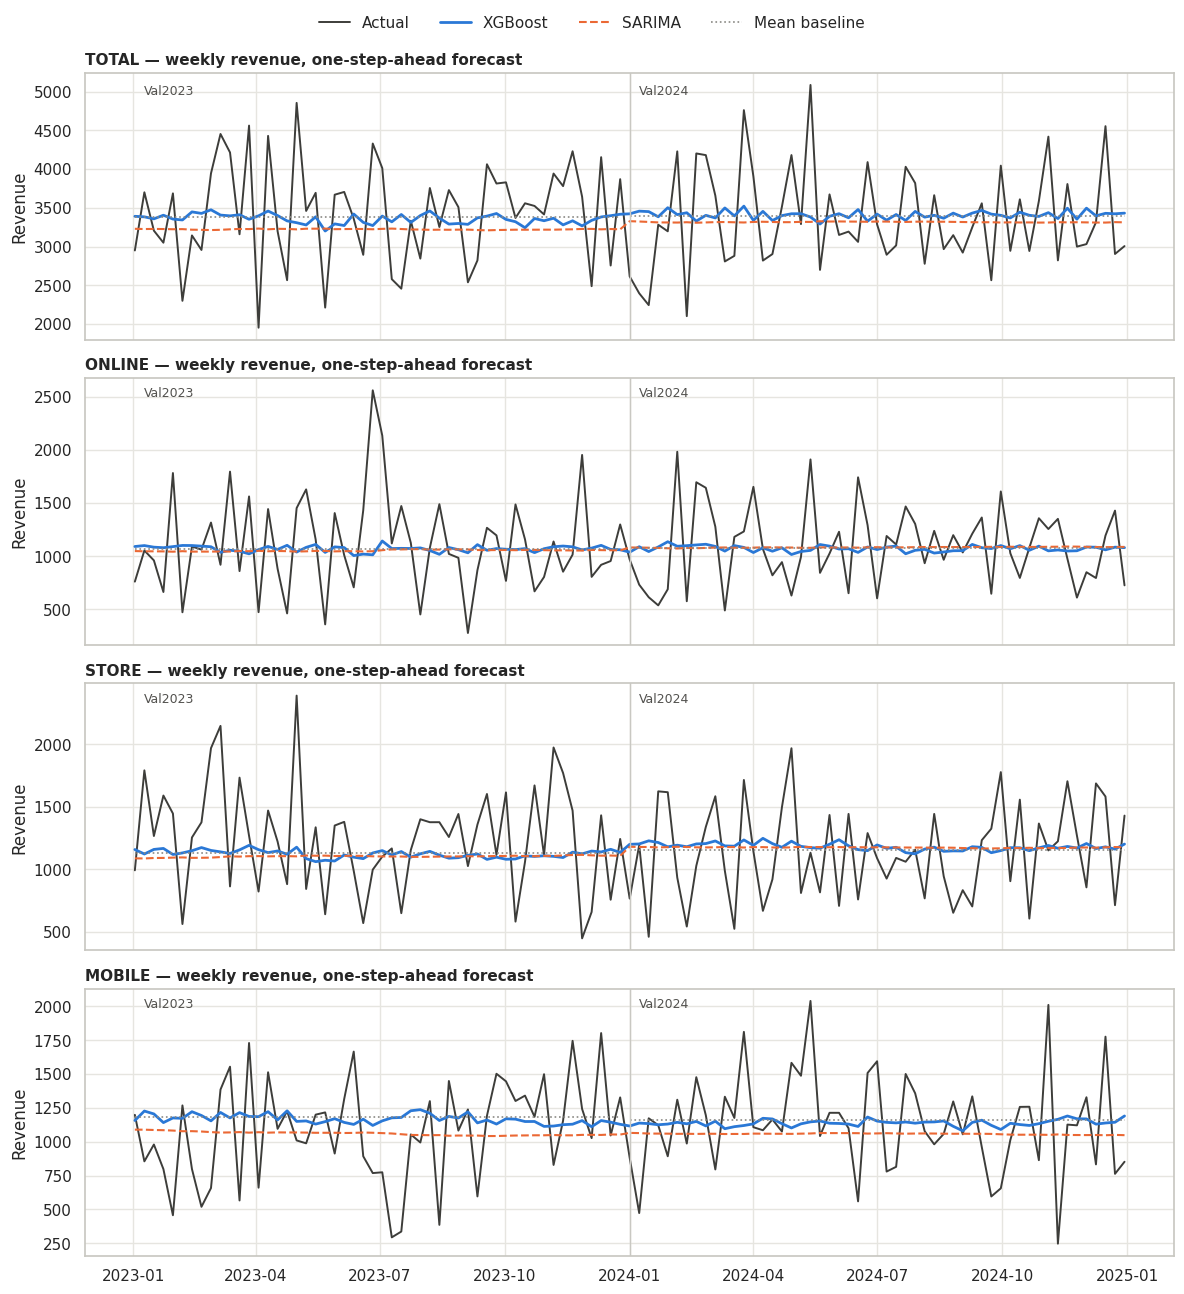

In [13]:
fig, axes = plt.subplots(len(SERIES), 1, figsize=(12, 3.25 * len(SERIES)), sharex=True, squeeze=False)
axes = axes[:, 0]
for ax, s in zip(axes, SERIES):
    actual = pd.concat([splits[s]["val_2023"], splits[s]["val_2024"]])["target_revenue"]
    xgb_p = pd.concat([preds[s]["val2023"], preds[s]["val2024"]])
    ax.plot(actual.index, actual, color=COLORS["actual"], lw=1.4, label="Actual")
    ax.plot(xgb_p.index, xgb_p, color=COLORS["xgb"], lw=2, label="XGBoost")
    sar = [tx.load_sarima(s, p, verbose=False) for p in tx.EVAL_PERIODS]
    if all(x is not None for x in sar):
        sar_p = pd.concat([x["sarima_forecast"] for x in sar])
        ax.plot(sar_p.index, sar_p, color=COLORS["sarima"], lw=1.5, ls="--", label="SARIMA")
    for i, (period, (tr_key, va_key)) in enumerate(tx.EVAL_PERIODS.items()):
        idx = splits[s][va_key].index
        ax.hlines(splits[s][tr_key]["target_revenue"].mean(), idx.min(), idx.max(),
                  color=COLORS["mean"], lw=1.2, ls=":", label="Mean baseline" if i == 0 else None)
    ax.axvline(pd.Timestamp("2024-01-01"), color="#c9c8c2", lw=1)
    ax.set_title(f"{s.upper()} — weekly revenue, one-step-ahead forecast", loc="left")
    ax.set_ylabel("Revenue")
    top = ax.get_ylim()[1]
    ax.text(pd.Timestamp("2023-01-09"), top * 0.97, "Val2023", va="top", color="#52514e", fontsize=9)
    ax.text(pd.Timestamp("2024-01-08"), top * 0.97, "Val2024", va="top", color="#52514e", fontsize=9)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=4, frameon=False, bbox_to_anchor=(0.5, 1.0))
fig.tight_layout(rect=(0, 0, 1, 0.975))
plt.show()

### 5.2. Feature importance (Gain & Weight)

- **Gain:** mức giảm loss trung bình mỗi lần feature được dùng để tách nhánh, cho biết feature "đóng góp bao nhiêu".
- **Weight:** số lần feature được dùng để tách nhánh, cho biết feature "được dùng bao nhiêu".
- Biểu đồ lấy model của giai đoạn Stability (fit trên 2019–2023), qua hàm `tx.feature_importance`, và chuẩn hóa importance để tổng bằng 1.
- ⚠️ Vì model gần như phẳng, importance ở đây chỉ phản ánh feature nào tạo ra **các dao động nhỏ** quanh mức trung bình. Không nên diễn giải thành "feature này dự báo tốt doanh thu".

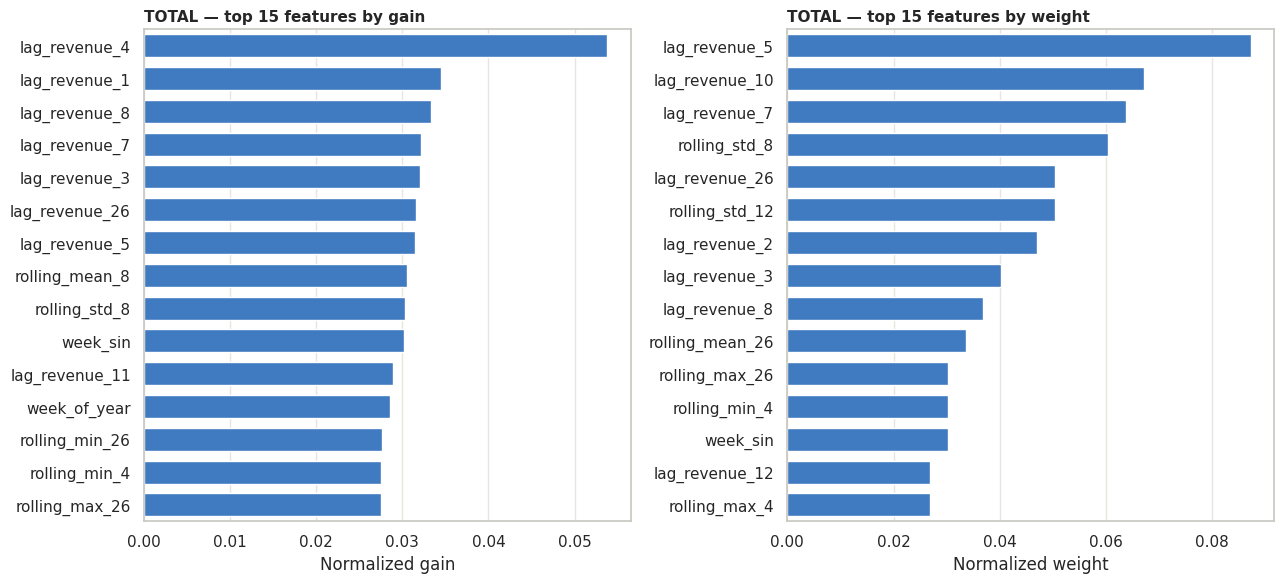

In [14]:
fi = {}
for s in SERIES:
    fi[s] = tx.feature_importance(models[s]["val2024"], FEATURES[s])
    fi[s]["group"] = fi[s]["feature"].map(tx.feature_group)

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ax, kind in zip(axes, ("gain", "weight")):
    top = fi["total"].sort_values(kind, ascending=False).head(15)
    sns.barplot(data=top, y="feature", x=kind, color=COLORS["xgb"], ax=ax, width=0.7)
    ax.set_title(f"TOTAL — top 15 features by {kind}", loc="left")
    ax.set_xlabel(f"Normalized {kind}")
    ax.set_ylabel("")
fig.tight_layout()
plt.show()

In [15]:
# Tỷ trọng gain theo nhóm feature, cả 4 chuỗi
group_share = pd.DataFrame({s: f.groupby("group")["gain"].sum() for s, f in fi.items()})
group_share.loc["Lag + Rolling"] = group_share.loc[["Lag", "Rolling"]].sum()
display(group_share.style.format("{:.1%}"))

# Top 5 feature theo gain mỗi chuỗi
pd.DataFrame({s: f.sort_values("gain", ascending=False)["feature"].head(5).values for s, f in fi.items()},
             index=[f"#{i}" for i in range(1, 6)])

,total,online,store,mobile
group,,,,
COVID,2.6%,0.0%,0.0%,3.0%
Lag,40.0%,39.7%,33.4%,34.3%
Outlier,2.5%,0.0%,0.0%,0.0%
Rolling,37.3%,43.5%,50.3%,39.5%
Time,13.1%,11.5%,12.1%,19.1%
YoY/MoM,4.6%,5.4%,4.1%,4.1%
Lag + Rolling,77.2%,83.2%,83.7%,73.8%


,total,online,store,mobile
#1,lag_revenue_4,lag_revenue_10,rolling_max_4,rolling_max_12
#2,lag_revenue_1,rolling_std_12,rolling_max_26,year
#3,lag_revenue_8,rolling_max_26,week_of_year,trend_index
#4,lag_revenue_7,lag_revenue_2,rolling_std_8,rolling_std_4
#5,lag_revenue_3,trend_index,rolling_max_12,rolling_std_26


## 6. Phân tích lỗi — Top tuần sai số lớn nhất (chuẩn bị deadline 13/10)

Bảng lỗi theo tuần lấy từ `tx.build_error_table` (cùng hàm script dùng để sinh `top_errors_*.csv`). Mỗi tuần được gắn các cờ sau:

| Cờ | Ý nghĩa |
|---|---|
| `is_covid_period` | Cờ COVID từ `preprocess.py` |
| `is_eda_iqr_outlier` | Outlier theo IQR trên toàn chuỗi 366 tuần, cùng quy tắc với báo cáo EDA. **Chỉ dùng để chẩn đoán, không phải feature** |
| `is_black_friday_week`, `is_cyber_monday_week`, `is_christmas_week` | Tuần (bắt đầu Thứ Hai) chứa Black Friday, Cyber Monday, hoặc 25/12 |
| `is_lag_1_high_revenue` | Tuần trước có doanh thu vượt p90, lấy từ feature của Tân |
| `sarima_abs_error` | Sai số tuyệt đối của SARIMA ở cùng tuần, để so sánh hai model |

In [16]:
FLAG_COLS = tx.FLAG_COLS
all_errors = pd.concat([tx.build_error_table(s, matrices[s], preds[s]) for s in SERIES], ignore_index=True)
top_errors = pd.concat([tx.build_error_table(s, matrices[s], preds[s], top_n=TOP_N) for s in SERIES],
                       ignore_index=True)

show = ["week_start", "period", "actual", "xgb_forecast", "residual", "pct_error", "sarima_abs_error"] + FLAG_COLS

def highlight_flags(col):
    return ["background-color: #fde9c8" if (col.name in FLAG_COLS and v == 1) else "" for v in col]

(top_errors[top_errors.series == "total"][show]
 .style.format({"actual": "{:,.0f}", "xgb_forecast": "{:,.0f}", "residual": "{:+,.0f}",
                "pct_error": "{:.1f}%", "sarima_abs_error": "{:,.0f}",
                "week_start": lambda d: d.strftime("%Y-%m-%d")})
 .apply(highlight_flags)
 .hide(axis="index")
 .set_caption(f"TOTAL — top {TOP_N} tuần sai số lớn nhất mỗi kỳ (ô tô màu = có cờ)"))

week_start,period,actual,xgb_forecast,residual,pct_error,sarima_abs_error,is_covid_period,is_eda_iqr_outlier,is_black_friday_week,is_cyber_monday_week,is_christmas_week,is_lag_1_high_revenue
2023-05-01,val2023,"4,854","3,308","+1,546",31.8%,"1,632",0,0,0,0,0,0
2023-04-03,val2023,"1,953","3,397","-1,443",73.9%,"1,279",0,0,0,0,0,1
2023-03-27,val2023,"4,561","3,352","+1,209",26.5%,"1,335",0,0,0,0,0,0
2023-06-26,val2023,"4,329","3,271","+1,058",24.4%,"1,106",0,0,0,0,0,0
2023-03-06,val2023,"4,452","3,406","+1,046",23.5%,"1,236",0,0,0,0,0,0
2023-02-06,val2023,"2,300","3,343","-1,043",45.3%,925,0,0,0,0,0,0
2023-05-22,val2023,"2,213","3,200",-988,44.6%,"1,019",0,0,0,0,0,0
2023-04-10,val2023,"4,428","3,458",+970,21.9%,"1,205",0,0,0,0,0,0
2023-07-17,val2023,"2,456","3,414",-957,39.0%,770,0,0,0,0,0,0
2023-11-20,val2023,"4,230","3,332",+897,21.2%,"1,007",0,0,1,0,0,0


In [17]:
# Các tuần lỗi lớn rơi vào sự kiện / cờ đã biết — cả 4 chuỗi
flagged = top_errors[top_errors.any_known_event == 1].copy()
flagged["flags"] = flagged[FLAG_COLS].apply(
    lambda r: ", ".join(c.replace("is_", "") for c in FLAG_COLS if r[c] == 1), axis=1)
display(flagged[["series", "period", "week_start", "actual", "xgb_forecast", "abs_error", "sarima_abs_error", "flags"]]
        .style.format({"actual": "{:,.0f}", "xgb_forecast": "{:,.0f}", "abs_error": "{:,.0f}",
                       "sarima_abs_error": "{:,.0f}", "week_start": lambda d: d.strftime("%Y-%m-%d")})
        .hide(axis="index"))

summary_err = top_errors.groupby(["series", "period"]).agg(
    n_top=("abs_error", "size"),
    n_known_event=("any_known_event", "sum"),
    xgb_better_than_sarima=("xgb_better_than_sarima", "sum"),
    share_under_forecast=("direction", lambda d: round((d == "under_forecast").mean(), 2)),
).reindex(SERIES, level=0)
display(summary_err)
print(f"Tổng: {int(top_errors.any_known_event.sum())}/{len(top_errors)} tuần lỗi lớn rơi vào sự kiện/cờ đã biết.")

series,period,week_start,actual,xgb_forecast,abs_error,sarima_abs_error,flags
total,val2023,2023-04-03,"1,953","3,397","1,443","1,279",lag_1_high_revenue
total,val2023,2023-11-20,"4,230","3,332",897,"1,007",black_friday_week
online,val2023,2023-06-26,"2,564","1,013","1,552","1,518",eda_iqr_outlier
online,val2023,2023-07-03,"2,137","1,143",994,"1,081","eda_iqr_outlier, lag_1_high_revenue"
online,val2023,2023-11-27,"1,955","1,059",896,902,cyber_monday_week
online,val2023,2023-02-06,471,"1,101",630,576,lag_1_high_revenue
online,val2024,2024-02-26,"1,645","1,112",533,567,lag_1_high_revenue
online,val2024,2024-02-12,575,"1,099",524,502,lag_1_high_revenue
store,val2023,2023-05-01,"2,391","1,177","1,214","1,288",eda_iqr_outlier
store,val2023,2023-03-06,"2,148","1,139","1,009","1,051",lag_1_high_revenue


n_top  n_known_event  xgb_better_than_sarima  share_under_forecast
series period                                                                     
total  val2023     10              2                       7                   0.6
       val2024     10              0                       6                   0.6
online val2023     10              4                       6                   0.5
       val2024     10              2                       5                   0.7
store  val2023     10              4                       5                   0.8
       val2024     10              0                       3                   0.4
mobile val2023     10              1                       3                   0.3
       val2024     10              1                       6                   0.6

Tổng: 14/80 tuần lỗi lớn rơi vào sự kiện/cờ đã biết.


In [18]:
# Nhận xét tự động: outlier EDA trong 2023–2024 và các tuần Black Friday / Cyber Monday
for _, r in all_errors[all_errors.is_eda_iqr_outlier == 1].iterrows():
    n_weeks = int(((all_errors.series == r.series) & (all_errors.period == r.period)).sum())
    print(f"- {r.series.upper():<6} {r.week_start.date()} (outlier EDA, actual {r.actual:,.0f}): "
          f"XGBoost dự báo {r.xgb_forecast:,.0f} → lỗi {r.abs_error:,.0f}, "
          f"xếp hạng #{r.error_rank}/{n_weeks} trong {r.period}")
for col, label in (("is_black_friday_week", "Black Friday"), ("is_cyber_monday_week", "Cyber Monday")):
    for _, r in all_errors[all_errors[col] == 1].sort_values(["week_start", "series"]).iterrows():
        print(f"- {label:<12} {r.week_start.date()} {r.series.upper():<6}: lỗi XGB {r.abs_error:,.0f} "
              f"| SARIMA {r.sarima_abs_error:,.0f} | hạng #{r.error_rank} "
              f"→ {'TRONG' if r.error_rank <= TOP_N else 'ngoài'} top-{TOP_N}")

- ONLINE 2023-06-26 (outlier EDA, actual 2,564): XGBoost dự báo 1,013 → lỗi 1,552, xếp hạng #1/52 trong val2023
- ONLINE 2023-07-03 (outlier EDA, actual 2,137): XGBoost dự báo 1,143 → lỗi 994, xếp hạng #2/52 trong val2023
- STORE  2023-05-01 (outlier EDA, actual 2,391): XGBoost dự báo 1,177 → lỗi 1,214, xếp hạng #1/52 trong val2023
- Black Friday 2023-11-20 MOBILE: lỗi XGB 617 | SARIMA 699 | hạng #8 → TRONG top-10
- Black Friday 2023-11-20 ONLINE: lỗi XGB 74 | SARIMA 39 | hạng #42 → ngoài top-10
- Black Friday 2023-11-20 STORE : lỗi XGB 332 | SARIMA 355 | hạng #23 → ngoài top-10
- Black Friday 2023-11-20 TOTAL : lỗi XGB 897 | SARIMA 1,007 | hạng #10 → TRONG top-10
- Black Friday 2024-11-25 MOBILE: lỗi XGB 48 | SARIMA 72 | hạng #47 → ngoài top-10
- Black Friday 2024-11-25 ONLINE: lỗi XGB 442 | SARIMA 481 | hạng #14 → ngoài top-10
- Black Friday 2024-11-25 STORE : lỗi XGB 99 | SARIMA 95 | hạng #44 → ngoài top-10
- Black Friday 2024-11-25 TOTAL : lỗi XGB 354 | SARIMA 315 | hạng #36 → ngoà

### 6.1. Residual còn tín hiệu không? (Ljung-Box — `tx.residual_whiteness`)

Nếu residual của XGBoost là nhiễu trắng (p > 0.05) thì model đã khai thác hết tín hiệu tự tương quan mà dữ liệu có.

In [19]:
lb_df = pd.DataFrame({s: tx.residual_whiteness(preds[s], matrices[s]) for s in SERIES}).T.rename_axis("series")
lb_df["white_noise (all p>0.05)"] = np.where((lb_df > 0.05).all(axis=1), "yes", "no")
lb_df

,ljung_p_lag4_val2023,ljung_p_lag10_val2023,ljung_p_lag4_val2024,ljung_p_lag10_val2024,white_noise (all p>0.05)
series,,,,,
total,0.5070,0.1640,0.3371,0.8072,yes
online,0.9787,0.2284,0.3868,0.5260,yes
store,0.4401,0.5013,0.2539,0.0745,yes
mobile,0.1733,0.7479,0.8752,0.8711,yes


### 6.2. Nhận xét chính cho phân tích lỗi

1. **Outlier EDA đều lọt top lỗi.** Cả 3 tuần outlier mà EDA đã ghi nhận trong giai đoạn 2023–2024 đều nằm trong top lỗi: Online 2023-06-26 và 2023-07-03, Store 2023-05-01. Model không dự báo được các đỉnh bất thường này, vì đường dự báo gần như phẳng.
2. **Black Friday / Cyber Monday: tín hiệu không nhất quán.** Năm 2023, tuần Black Friday (2023-11-20) nằm trong top lỗi của Total và Mobile, tuần Cyber Monday (2023-11-27) nằm trong top lỗi của Online và Store. Nhưng sang 2024, không tuần sự kiện nào lọt top lỗi. Ma trận feature hiện **chưa có cờ lịch sự kiện**; đây là ngày biết trước nên thêm vào không gây leakage. Tuy vậy, với chỉ 4–5 lần Black Friday trong tập train và hiệu ứng không lặp lại đều, khả năng cải thiện có thể thấp. Nên thử, đo lại RMSE, và trao đổi với Tân trước.
3. **Phần lớn lỗi là nhiễu.** Chỉ 14/80 tuần lỗi lớn gắn với sự kiện hoặc cờ đã biết. Kiểm định Ljung-Box (mục 6.1) cho thấy residual của XGBoost là nhiễu trắng ở cả 8 trường hợp (p > 0.05): model không bỏ sót cấu trúc tự tương quan nào. Phần lỗi còn lại là các cú tăng/giảm ngẫu nhiên mà cả SARIMA lẫn XGBoost đều trượt.
4. **Ý nghĩa cho Hybrid.** Residual của SARIMA ≈ actual − hằng số, tức gần như vẫn là nhiễu. XGBoost học trên residual khó cải thiện đáng kể. Cần thống nhất với Tân và Ý trước khi làm bước Hybrid.

**Việc tiếp theo:**

- Chia MAE theo nhóm tuần (có sự kiện / outlier / bình thường).
- Thử thêm cờ Black Friday, Cyber Monday và Giáng sinh làm feature, rồi đo lại RMSE.
- So sánh lỗi XGBoost và SARIMA theo từng tuần.

## 7. Đối chiếu với output của `src/train_xgboost.py`

Ô này kiểm tra 3 điều:

1. Dự báo của notebook trùng **tuyệt đối** với CSV mà script đã lưu.
2. Trong CSV, cột `residual` bằng **đúng** `actual − xgb_forecast` (nhờ ép kiểu float64). Lưu ý: cần đọc bằng `pd.read_csv(..., float_precision="round_trip")`. Với bộ đọc mặc định của pandas, có thể lệch khoảng 1e-13 ở chữ số cuối, không ảnh hưởng gì.
3. Metric của notebook khớp với `xgb_summary_all_series.csv`.

In [20]:
check = []
summary_path = ROOT / "outputs/xgboost/xgb_summary_all_series.csv"
summary_csv = pd.read_csv(summary_path).set_index("series") if summary_path.exists() else None
for s in SERIES:
    for period in tx.EVAL_PERIODS:
        path = ROOT / f"outputs/xgboost/forecast_{period}_{s}.csv"
        if not path.exists():
            check.append({"series": s, "period": period, "status": "chưa có file (chưa chạy script)"})
            continue
        # float_precision="round_trip": đọc lại đúng từng bit giá trị float64 đã ghi
        csv = pd.read_csv(path, parse_dates=["week_start"], float_precision="round_trip").set_index("week_start")
        forecast_diff = float((csv["xgb_forecast"] - preds[s][period]).abs().max())
        residual_diff = float((csv["residual"] - (csv["actual"] - csv["xgb_forecast"])).abs().max())
        row = {"series": s, "period": period, "forecast_max_abs_diff": forecast_diff,
               "csv_residual_consistency_diff": residual_diff}
        if summary_csv is not None:
            yr = period[-4:]
            mine = results[(results.series == s) & (results.period == period) & (results.model == "XGBoost")].iloc[0]
            row["metrics_match_summary"] = all(
                np.isclose(summary_csv.loc[s, f"{k}_{yr}"], mine[k], rtol=0, atol=1e-9)
                for k in ("rmse", "mae", "wape", "smape"))
        row["status"] = "KHỚP" if forecast_diff == 0 and residual_diff == 0 and row.get("metrics_match_summary", True) else "LỆCH"
        check.append(row)
pd.DataFrame(check)

,series,period,forecast_max_abs_diff,csv_residual_consistency_diff,metrics_match_summary,status
0,total,val2023,0.0,0.0,True,KHỚP
1,total,val2024,0.0,0.0,True,KHỚP
2,online,val2023,0.0,0.0,True,KHỚP
3,online,val2024,0.0,0.0,True,KHỚP
4,store,val2023,0.0,0.0,True,KHỚP
5,store,val2024,0.0,0.0,True,KHỚP
6,mobile,val2023,0.0,0.0,True,KHỚP
7,mobile,val2024,0.0,0.0,True,KHỚP
